# 9f. Dynamics of the simulated SSWs

Are E3SM's SSWs realistic? Lag composites of every model SSW (raw wind; every start, case and
member-winter) against ERA5 1979-2025, season-matched to the model's onset months.

1. **Composites**: U(60°N, 10 hPa), the 100-hPa eddy heat flux, polar-cap height (time-height).
2. **Event properties**: pre-onset wave forcing, minimum wind, easterly days, recovery, persistence.
3. **Vertical evolution**: polar-cap anomalies at 10-500 hPa and polar-cap SLP in pre- and post-onset windows.

**Findings.** Model SSWs are late-season (half in March), shallow and brief (median minimum wind about
-3 vs -9 m/s; recovery about 4 vs 8 days, then a rebound to about +14 m/s), driven by weaker 100-hPa
heat flux (about 16 vs 27 K m/s; partly the daily-mean sampling). Their polar-cap anomaly appears at all
levels at once and lasts longer in the lower stratosphere; the simultaneous tropospheric signal suggests
co-variability (a post-onset tropospheric association), not a demonstrated downward influence.

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

### Run controls

In [2]:
NOTEBOOK = "9f_ssw_dynamics"   # outputs: rc.OUTPUT_ROOT/9f_ssw_dynamics/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX


fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.75 s, sys: 1.07 s, total: 3.82 s
Wall time: 35.1 s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

In [5]:
%%time
M = sd.load_model(cfg, E, R)                  # pooled 2026 starts: zonal means, climatologies, daily indices
monthly, daily, lead_clim, z_offset = M.monthly, M.daily, M.lead_clim, M.z_offset
m_u60, m_u60_clim, m_u60_adj, m_pch, m_vt = M.u60, M.u60_clim, M.u60_adj, M.pch, M.vt
mm_u60, mm_u60_anom, mm_qbo = M.mm_u60, M.mm_u60_anom, M.mm_qbo

[init Feb 2026] 20 members, daily 01 Feb 2026 - 31 Jan 2028; climatology: Reanalysis init02 6 starts 1985-2010 (every fifth year)


[init May 2026] 30 members, daily 01 May 2026 - 30 Apr 2028; climatology: Reanalysis init05 1981-2010


[init Aug 2026] 30 members, daily 01 Aug 2026 - 31 Jul 2028; climatology: Reanalysis init08 6 starts 1985-2010 (every fifth year)


[init Nov 2026] 30 members, daily 01 Nov 2026 - 31 Oct 2028; climatology: Reanalysis init11 1981-2010
CPU times: user 3.21 s, sys: 1.63 s, total: 4.85 s
Wall time: 16.3 s


In [6]:
C = sd.ssw_catalogue(cfg, E, M)               # SSW central dates and event properties (raw and bias-adjusted)
obs_events, obs_winters, obs_counts = C.obs_events, C.obs_winters, C.obs_counts
model_ssw, model_ssw_adj, events_all = C.model_ssw, C.model_ssw_adj, C.events
mid_month, case_of, djf_mean, DJF_DAYS = sd.mid_month, sd.case_of, sd.djf_mean, sd.DJF_DAYS

### 1. Composites

Lag composites around the central dates of the model SSWs (raw wind; every start, case and member-winter)
against ERA5 1979-2025.

* **Season matching.** The model events fall mostly in Feb-Mar and ERA5's in Jan-Feb, so the principal
  ERA5 composite weights each observed event by the ratio of the model and ERA5 onset-month frequencies
  (thin line: unweighted ERA5).
* **Coverage.** Only events with the whole `COMPOSITE_WINDOW` in the record enter (the count left out is printed).
* **Uncertainty.** Shading is the 90% interval of the composite **mean** from a cluster bootstrap
  (model: member trajectories, so a member's two winters stay together; ERA5: winters); dotted lines
  are the 10-90% spread of the events.
* **Heat flux** [v*T*] at 100 hPa, 45-75°N, is shown as absolute values: there is no daily model
  reference climatology for an anomaly. The model value is the eddy covariance of the daily-mean V and
  T within each latitude band; sub-daily eddies are missing (the 6-hourly output has no 100-hPa V, T).
* **Polar-cap height** (60-90°N, anomaly / ERA5 daily σ) as time-height sections, then the
  **event-level distributions** and a table of the anomaly at 10-500 hPa and of the polar-cap
  sea-level pressure over pre-onset and successive post-onset windows. The polar-cap SLP is the surface
  index; a positive post-onset anomaly is a **post-onset tropospheric association** (negative NAM),
  not by itself evidence of a causal downward influence (cf. Baldwin and Dunkerton 2001).

The model polar-cap heights use the daily-minus-monthly offset correction (section 2). Its check (the
printout there) shows it is nearly constant across leads, seasons and starts, i.e. a processing
difference and not part of the evolving signal.

events with the whole (-30, 60) window: ERA5 32 of 32, E3SM 59 of 96
onset months, model / ERA5 (fractions):


/tmp/ipykernel_558418/849560413.py:41: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  m_comp = {k: xr.concat(v, dim="event") for k, v in m_parts.items()} if m_months else None
/tmp/ipykernel_558418/849560413.py:41: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  m_comp = {k: xr.concat(v, dim="event") for k, v in m_p

,1,2,3,11,12
E3SM,0.17,0.22,0.47,0.00,0.14
ERA5,0.31,0.38,0.16,0.03,0.12


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9f_ssw_dynamics/figures/fig_ssw_composite_2026.png


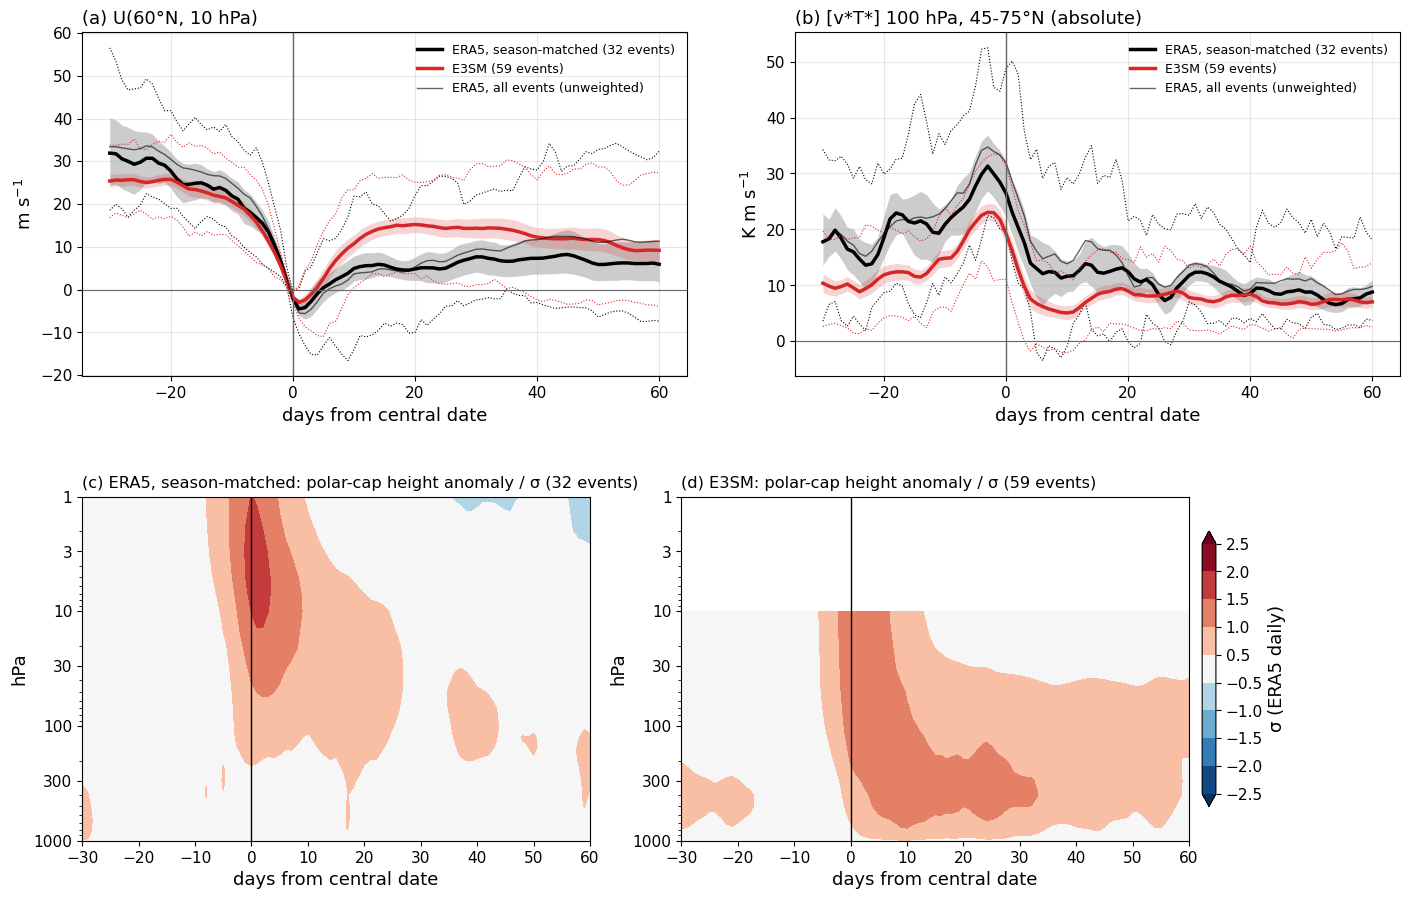

In [7]:
COMPOSITE_WINDOW = (-30, 60)          # days that must all be in the record
PRE_WINDOW, PCH_WINDOWS = (-20, -1), [(-20, -1), (0, 14), (15, 29), (30, 59)]
PCH_LEVELS = [10.0, 50.0, 100.0, 300.0, 500.0]
NBOOT = 2000

# polar-cap SLP: ERA5 and model (drift-corrected PSL climatology), standardized by the ERA5 daily sigma
e_slp = sc.era5_polar_cap_slp(ERA5_DAILY_DIR, years=(ERA5_FIRST_YEAR, YEAR))
slp_clim, slp_std = sc.daily_climatology(e_slp, CLIM_YEARS)
e_slp_s = (e_slp - on_days(slp_clim, e_slp)) / on_days(slp_std, e_slp)
m_slp_s = {}
for init in INIT_MONTHS:
    d = daily[init]
    pc = sc.lat_mean(rc.matched_climatology("PSL", init, method=CLIM_METHOD, mode=derivation_mode).mean("lon"), sc.PCAP)
    clim = sc.daily_from_lead(pc, YEAR, init, d["time"].values).assign_coords(time=d["time"])
    raw = sc.lat_mean(d["PSL"], sc.PCAP)
    m_slp_s[init] = (raw - clim) / on_days(slp_std, raw)

lags = np.arange(COMPOSITE_WINDOW[0], COMPOSITE_WINDOW[1] + 1)


def windows(series, dates):
    return sc.lag_composite(series, dates, lags)


# ERA5 composites, clusters (winters) and season-matching weights
e_dates = list(obs_events["central_date"])
e_comp = {"u": windows(e_u60, e_dates), "vt": windows(e_vt, e_dates), "pch": windows(e_pch, e_dates), "slp": windows(e_slp_s, e_dates)}
e_full = np.isfinite(e_comp["u"].values).all(axis=1)
e_months = np.array([d.month for d in e_dates])
e_clusters = np.array([sc.winter_of(d) for d in e_dates])

# model composites (raw-wind events), clusters (start x member trajectory)
m_parts, m_months, m_clusters = {k: [] for k in e_comp}, [], []
for init in INIT_MONTHS:
    for _, ev in model_ssw[init].iterrows():
        mem, d = ev["series"], ev["central_date"]
        for key, src in (("u", m_u60[init]), ("vt", m_vt[init]), ("pch", m_pch[init]), ("slp", m_slp_s[init])):
            m_parts[key].append(windows(src.sel(member=mem), [d]))
        m_months.append(d.month)
        m_clusters.append(f"{init}:{mem}")
m_comp = {k: xr.concat(v, dim="event") for k, v in m_parts.items()} if m_months else None
m_months, m_clusters = np.array(m_months), np.array(m_clusters)
m_full = np.isfinite(m_comp["u"].values).all(axis=1) if m_comp else np.array([], bool)
print(f"events with the whole {COMPOSITE_WINDOW} window: ERA5 {e_full.sum()} of {e_full.size}, "
      f"E3SM {m_full.sum()} of {m_full.size}")

# season-matching weights of the ERA5 events (model onset-month frequency / ERA5 onset-month frequency)
p_mod = pd.Series(m_months[m_full]).value_counts(normalize=True)
p_obs = pd.Series(e_months[e_full]).value_counts(normalize=True)
e_w = np.array([p_mod.get(m, 0.0) / p_obs[m] if f else 0.0 for m, f in zip(e_months, e_full)])
missing = sorted(set(p_mod.index) - set(p_obs.index))
if missing:
    print(f"[note] model onset months with no ERA5 event: {missing}; the matched ERA5 composite cannot represent them")
print("onset months, model / ERA5 (fractions):")
display(pd.DataFrame({"E3SM": p_mod, "ERA5": p_obs}).fillna(0).sort_index().round(2).T)


def comp_stats(comp, full, weights, clusters, boot=True):
    # weighted mean, cluster-bootstrap 90% CI of the mean, and the 10-90% event spread
    x = comp.values[full]
    w = np.asarray(weights, float)[full]
    mean = np.nansum(x * w.reshape((-1,) + (1,) * (x.ndim - 1)), 0) / w.sum()
    if not boot:
        return mean
    cl = np.asarray(clusters)[full]
    labs = np.unique(cl)
    idx = {l: np.flatnonzero(cl == l) for l in labs}
    boot = []
    for _ in range(NBOOT):
        ev = np.concatenate([idx[l] for l in rng.choice(labs, labs.size)])
        boot.append(np.nansum(x[ev] * w[ev].reshape((-1,) + (1,) * (x.ndim - 1)), 0) / w[ev].sum())
    boot = np.asarray(boot)
    return mean, np.nanpercentile(boot, 5, 0), np.nanpercentile(boot, 95, 0), np.nanpercentile(x, 10, 0), np.nanpercentile(x, 90, 0)


ones_m = np.ones(m_full.size)
ones_e = np.where(e_full, 1.0, 0.0)
fig = plt.figure(figsize=(17, 10.5))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.18)
for k, (key, title, units) in enumerate([("u", f"(a) U(60°N, {REF_LEVEL:g} hPa)", "m s$^{-1}$"),
                                         ("vt", "(b) [v*T*] 100 hPa, 45-75°N (absolute)", "K m s$^{-1}$")]):
    ax = fig.add_subplot(gs[0, k])
    for comp, full, w, cl, color, label in ((e_comp[key], e_full, e_w, e_clusters, "k", "ERA5, season-matched"),
                                            (m_comp[key], m_full, ones_m, m_clusters, "tab:red", "E3SM")):
        mu, lo, hi, p10, p90 = comp_stats(comp, full, w, cl)
        ax.fill_between(lags, lo, hi, color=color, alpha=0.2, lw=0)
        ax.plot(lags, mu, color=color, lw=2.5, label=f"{label} ({int(full.sum())} events)")
        ax.plot(lags, p10, color=color, lw=0.8, ls=":")
        ax.plot(lags, p90, color=color, lw=0.8, ls=":")
    mu_raw = comp_stats(e_comp[key], e_full, ones_e, e_clusters)[0]
    ax.plot(lags, mu_raw, color="k", lw=1, alpha=0.6, label="ERA5, all events (unweighted)")
    ax.axvline(0, color="0.4", lw=1)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_xlabel("days from central date")
    ax.set_ylabel(units)
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, fontsize=fontz * 0.7)
    ax.grid(alpha=0.3)
pch_lev = np.array([-2.5, -2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2, 2.5])
for k, (comp, full, w, label) in enumerate(((e_comp["pch"], e_full, e_w, "ERA5, season-matched"), (m_comp["pch"], m_full, ones_m, "E3SM"))):
    ax = fig.add_subplot(gs[1, k])
    mu = xr.DataArray(comp_stats(comp, full, w, None, boot=False), dims=("lag", "plev"),
                      coords={"lag": lags, "plev": comp["plev"].values})
    c = mu.sel(plev=slice(1, 1000)).dropna("plev", how="all")
    cf = ax.contourf(c["lag"], c["plev"], c.T, levels=pch_lev, cmap="RdBu_r", extend="both")
    ax.set_yscale("log")
    ax.set_ylim(1000, 1 if label.startswith("ERA5") else 10)
    ax.set_yticks([1000, 300, 100, 30, 10, 3, 1], ["1000", "300", "100", "30", "10", "3", "1"])
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("days from central date")
    ax.set_ylabel("hPa")
    ax.set_title(f"({'cd'[k]}) {label}: polar-cap height anomaly / σ ({int(full.sum())} events)", loc="left", fontsize=fontz * 0.9)
fig.colorbar(cf, ax=fig.axes[2:], label="σ (ERA5 daily)", shrink=0.8, pad=0.01)
save(fig, "ssw", "composite", YEAR)
plt.show()

### 2. Event properties and vertical evolution

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9f_ssw_dynamics/figures/fig_ssw_event_properties_2026.png


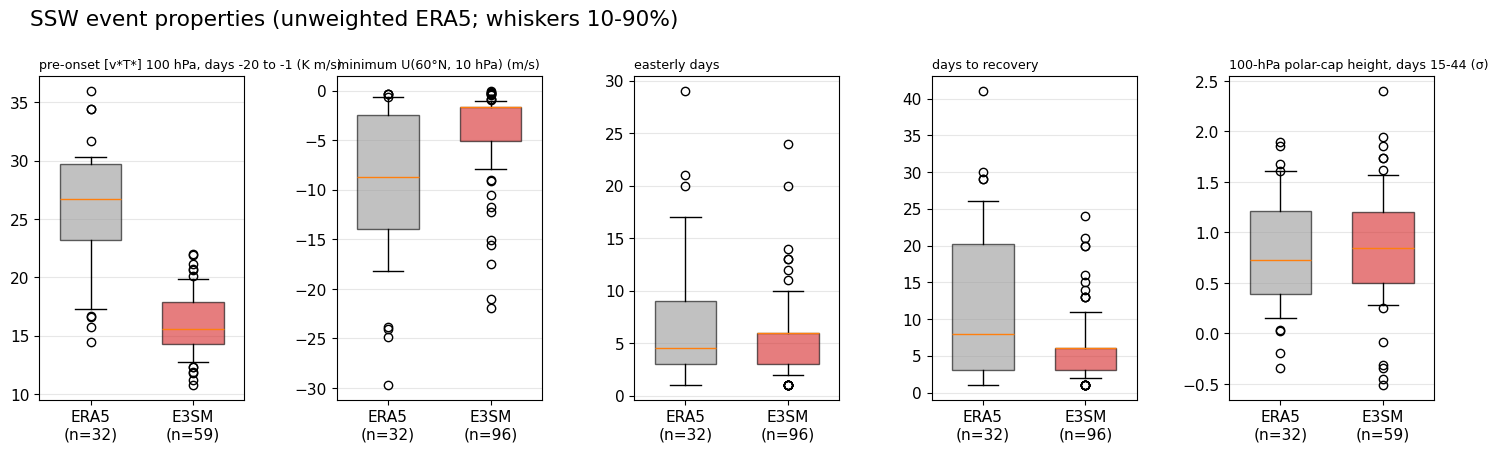

Polar-cap (60-90°N) anomalies around the SSW central dates (composite means; positive SLP: negative NAM):


,set,days,Z 10 hPa (σ),Z 50 hPa (σ),Z 100 hPa (σ),Z 300 hPa (σ),Z 500 hPa (σ),SLP (σ)
0,"ERA5, season-matched",-20 to -1,0.32,0.20,0.21,0.30,0.29,0.11
1,"ERA5, season-matched",0 to 14,1.16,0.86,0.68,0.18,0.16,0.11
2,"ERA5, season-matched",15 to 29,0.52,0.67,0.60,0.16,0.14,0.10
3,"ERA5, season-matched",30 to 59,-0.01,0.39,0.46,0.21,0.18,0.12
4,E3SM,-20 to -1,0.28,0.31,0.29,0.29,0.28,-0.24
5,E3SM,0 to 14,0.99,1.12,1.14,1.12,1.07,0.50
6,E3SM,15 to 29,0.27,0.72,0.91,1.09,1.07,0.45
7,E3SM,30 to 59,0.11,0.62,0.75,0.77,0.73,0.11


In [8]:
# Event-level distributions and the vertical evolution table
def event_values(comp, full, lag_range, plev=None):
    c = comp.sel(lag=slice(*lag_range))
    if plev is not None:
        c = c.sel(plev=plev)
    return c.mean("lag").values[full]


cat_raw = events_all[events_all["wind"].isin(["ERA5", "raw"])]
cat_raw = cat_raw.assign(group=np.where(cat_raw["source"] == "ERA5", "ERA5", "E3SM"))
metrics = {
    f"pre-onset [v*T*] 100 hPa, days {PRE_WINDOW[0]} to {PRE_WINDOW[1]} (K m/s)":
        (event_values(e_comp["vt"], e_full, PRE_WINDOW), event_values(m_comp["vt"], m_full, PRE_WINDOW)),
    "minimum U(60°N, 10 hPa) (m/s)": (cat_raw.query("group == 'ERA5'")["min_u"].values, cat_raw.query("group == 'E3SM'")["min_u"].values),
    "easterly days": (cat_raw.query("group == 'ERA5'")["easterly_days"].values, cat_raw.query("group == 'E3SM'")["easterly_days"].values),
    "days to recovery": (cat_raw.query("group == 'ERA5'")["days_to_recovery"].dropna().values,
                         cat_raw.query("group == 'E3SM'")["days_to_recovery"].dropna().values),
    "100-hPa polar-cap height, days 15-44 (σ)":
        (event_values(e_comp["pch"], e_full, (15, 44), 100.0), event_values(m_comp["pch"], m_full, (15, 44), 100.0)),
}
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4.2), gridspec_kw={"wspace": 0.45})
for ax, (name, (eo, mo)) in zip(axes, metrics.items()):
    bp = ax.boxplot([eo[np.isfinite(eo)], mo[np.isfinite(mo)]], patch_artist=True, widths=0.6, whis=(10, 90))
    for patch, c in zip(bp["boxes"], ("0.6", "tab:red")):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    ax.set_xticks([1, 2], [f"ERA5\n(n={np.isfinite(eo).sum()})", f"E3SM\n(n={np.isfinite(mo).sum()})"])
    ax.set_title(name, fontsize=fontz * 0.7, loc="left", wrap=True)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("SSW event properties (unweighted ERA5; whiskers 10-90%)", x=0.12, ha="left", y=1.04)
save(fig, "ssw", "event_properties", YEAR)
plt.show()

rows = []
for label, comp, full, w in (("ERA5, season-matched", e_comp, e_full, e_w), ("E3SM", m_comp, m_full, ones_m)):
    for win in PCH_WINDOWS:
        row = {"set": label, "days": f"{win[0]} to {win[1]}"}
        for p in PCH_LEVELS:
            v = comp["pch"].sel(plev=p, lag=slice(*win)).mean("lag").values[full]
            row[f"Z {p:g} hPa (σ)"] = np.nansum(v * w[full]) / w[full].sum()
        v = comp["slp"].sel(lag=slice(*win)).mean("lag").values[full]
        row["SLP (σ)"] = np.nansum(v * w[full]) / w[full].sum()
        rows.append(row)
vertical = pd.DataFrame(rows)
vertical.to_csv(DATA_DIR / f"ssw_vertical_evolution_{YEAR}.csv", index=False)
print("Polar-cap (60-90°N) anomalies around the SSW central dates (composite means; positive SLP: negative NAM):")
display(vertical.round(2))